# Who is who in EHR generation?

### Description

The dataset contains a mixture of demographic, clinical, laboratory, diagnosis, utilization, and discharge-related variables. Examples include age, BMI, blood pressure, heart rate, glucose, creatinine, diagnosis category, smoking status, number of medications, previous visits, and length of stay.

All records are fully synthetic and do not correspond to real patients.

The target variable contains four anonymized classes:
- Model_A
- Model_B
- Model_C
- Model_D

These correspond to four different LLMs used to generate the data.

For this challenge, the predictive model must be Logistic Regression. Participants are encouraged to improve performance through representation and preprocessing rather than by changing the classifier. Useful directions may include categorical encoding, missing-value strategies, scaling, binning, transformations, interaction features, and clinically motivated feature engineering.

### Files

- train.csv - the training set
- test.csv - the test set
- sample_submission.csv - a sample submission file in the correct format

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler, FunctionTransformer, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [3]:
# amaga el warning q surt cada cop q evaluem amb el model q demana al campus
import warnings

warnings.filterwarnings(
    "ignore",
    message="'penalty' was deprecated in version 1.8",
    category=FutureWarning
)

In [4]:
train = pd.read_csv('./train.csv')
test = pd.read_csv('./test.csv')

## Com és aquest dataset?

In [5]:
print(train.shape)
train.head()

(2400, 26)


,id,age,sex,bmi,smoking_status,encounter_type,systolic_bp,diastolic_bp,heart_rate,respiratory_rate,...,diabetes,hypertension,chronic_kidney_disease,primary_diagnosis,num_medications,prior_visits_12m,length_of_stay_days,discharge_destination,readmitted_30d,label
0,5be091fe7010722968d37fbbbfa5adec,38,Male,30.4,Current,Urgent,160,95,105,28,...,No,No,No,Respiratory,6,10,3.0,Home,No,Model_B
1,7ebc8ab8f1dfede1237163cb2e71325f,48,Female,28.5,Current,Elective,128,76,78,16,...,No,No,No,Gastrointestinal,3,2,2.0,Home,No,Model_D
2,69f51e35fec3bda1d81f2cbf9ac8b827,53,Female,25.4,Never,Elective,130,78,77,19,...,No,No,No,Renal,1,1,3.0,Rehabilitation,No,Model_A
3,8c64aa346b72cad6cb179f254abfd71d,45,Male,28.2,Never,Elective,145,95,72,18,...,Yes,No,No,Cardiovascular,4,0,4.0,Home,No,Model_C
4,c8255d88bcfc566c5616bed411b55bd7,41,Male,27.9,Current,Emergency,150,94,115,22,...,No,No,No,Gastrointestinal,2,5,3.0,HomeHealth,No,Model_B


In [6]:
train.info(verbose=True, max_cols= 30, show_counts= True)

<class 'pandas.DataFrame'>
RangeIndex: 2400 entries, 0 to 2399
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id                      2400 non-null   str    
 1   age                     2400 non-null   int64  
 2   sex                     2400 non-null   str    
 3   bmi                     2132 non-null   float64
 4   smoking_status          2400 non-null   str    
 5   encounter_type          2400 non-null   str    
 6   systolic_bp             2400 non-null   int64  
 7   diastolic_bp            2400 non-null   int64  
 8   heart_rate              2400 non-null   int64  
 9   respiratory_rate        2400 non-null   int64  
 10  temperature_c           2400 non-null   float64
 11  spo2                    2400 non-null   int64  
 12  glucose_mg_dl           1864 non-null   float64
 13  creatinine_mg_dl        1828 non-null   float64
 14  sodium_mmol_l           1900 non-null   float64
 15

Tenim 25 variables, 24 que aniran a X i 1 que anirà a Y. Veiem que la variable que volem aïllar es la variable 'label'. També podem veure que hi han variables amb nombre null (bmi,glucose_mg_dl, creatinine_mg_dl, sodium_mmol_l, hemoglobin_g_dl  )

In [7]:
# 1. Afegim una columna temporal amb el recompte de nuls per fila
train['total_nuls'] = train.isnull().sum(axis=1)

# 2. Veure les files ordenades de la que té més nuls a la que menys
files_mes_nuls = train.sort_values(by='total_nuls', ascending=False)

# Mostrem les columnes clau i quants nuls té cada fila
print(files_mes_nuls[['id', 'total_nuls', 'bmi', 'glucose_mg_dl', 'creatinine_mg_dl', 'sodium_mmol_l', 'hemoglobin_g_dl']].head(10))

# 3. Saber quantes files tenen 0 nuls, 1 nul, 2 nuls, etc.
recompte_per_quantitat = train['total_nuls'].value_counts().sort_index()
print("\nDistribució del nombre de nuls per fila:")
print(recompte_per_quantitat)

                                    id  total_nuls   bmi  glucose_mg_dl  \
673   88985a58066fd1b4126f4fddba57caba           5   NaN            NaN   
1292  e1c37322a419371f50e2e335266e44f8           5   NaN            NaN   
968   85b1d3e726779cf3c74af2c2622a2f84           5   NaN            NaN   
994   1a0f8dccf247846b416cdd8f65e1def3           5   NaN            NaN   
1934  c61116f17eef6514884e1821d650176e           5   NaN            NaN   
2064  eb2133078cb22f1b6542a9585cf98822           5   NaN            NaN   
49    a6e821f9706c1231898e699b49e9cb9e           5   NaN            NaN   
1483  779c568352348fbd9b11038960f3ccc2           5   NaN            NaN   
562   2a718f45e5d6033f8a92302cd9078607           4  24.3            NaN   
838   fa4f8ce7102b014dfca76eb671c2b496           4  30.7            NaN   

      creatinine_mg_dl  sodium_mmol_l  hemoglobin_g_dl  
673                NaN            NaN              NaN  
1292               NaN            NaN              NaN  
968

Amb el que ens quedem del script anterior es aixo: 

Distribució del nombre de nuls per fila:
total_nuls
0    932
1    816
2    460
3    136
4     48
5      8

On les files on tenim 5 son les seguents:

673   -88985a58066fd1b4126f4fddba57caba     
1292  -e1c37322a419371f50e2e335266e44f8         
968   -85b1d3e726779cf3c74af2c2622a2f84      
994   -1a0f8dccf247846b416cdd8f65e1def3         
1934  -c61116f17eef6514884e1821d650176e          
2064  -eb2133078cb22f1b6542a9585cf98822            
49    -a6e821f9706c1231898e699b49e9cb9e

-> Eliminem aquestes 5 files

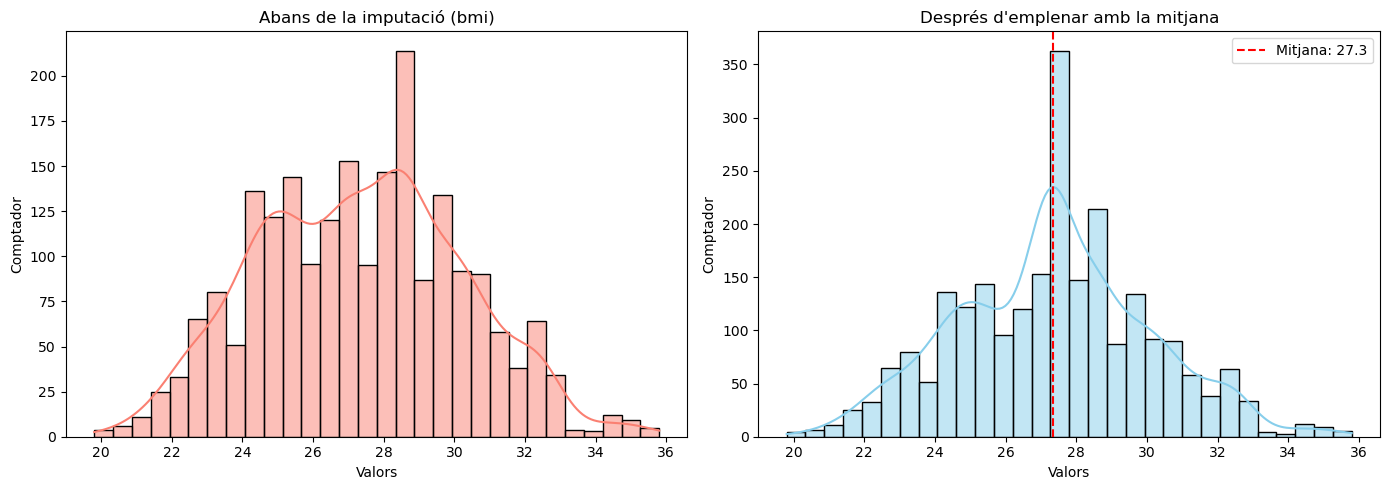

In [35]:
# Triem una variable amb valors nuls
variable = 'bmi'

plt.figure(figsize=(14, 5))

# --- GRÀFIC 1: ABANS (Només dades reals, descartant nuls) ---
plt.subplot(1, 2, 1)
sns.histplot(train[variable].dropna(), kde=True, color='salmon', bins=30)
plt.title(f"Abans de la imputació ({variable})")
plt.xlabel("Valors")
plt.ylabel("Comptador")

# --- GRÀFIC 2: DESPRÈS (Emplenant els nuls amb la mitjana) ---
df_imputat = train.copy()
mitjana_val = df_imputat[variable].mean()
df_imputat[variable] = df_imputat[variable].fillna(mitjana_val)

plt.subplot(1, 2, 2)
sns.histplot(df_imputat[variable], kde=True, color='skyblue', bins=30)
plt.axvline(mitjana_val, color='red', linestyle='--', label=f'Mitjana: {mitjana_val:.1f}')
plt.title(f"Després d'emplenar amb la mitjana")
plt.xlabel("Valors")
plt.ylabel("Comptador")
plt.legend()

plt.tight_layout()
plt.show()

Anem a dividir les variables per una millor comprensió:

**categòriques**
- sense ordre:
    - id  ->  ( crec q es pot eliminar )
    - primary_diagnosis
    - discharge_destination
    - label ( variable objectiu)
- amb ordre:
    - smoking status
    - encounter_type
- si/no o A/B:
    - sex
    - diabetes
    - hypertension
    - chronic_kidney_disease
    - discharge_destination

**numériques**
- quantitativa:
    - age (int64): Edat.
    - systolic_bp (int64): Pressió arterial sistòlica.
    - diastolic_bp (int64): Pressió arterial diastòlica.
    - heart_rate (int64): Freqüència cardíaca.
    - respiratory_rate (int64): Freqüència respiratòria.
    - spo2 (int64): Saturació d'oxigen.
    - num_medications (int64): Nombre de medicaments.
    - prior_visits_12m (int64): Visites prèvies en els últims 12 mesos.
- contínua:
    - bmi (float64): Índex de massa corporal.
    - temperature_c (float64): Temperatura en graus Celsius.
    - glucose_mg_dl (float64): Nivell de glucosa.
    - creatinine_mg_dl (float64): Nivell de creatinina.
    - sodium_mmol_l (float64): Nivell de sodi.
    - hemoglobin_g_dl (float64): Nivell d'hemoglobina.
    - length_of_stay_days (float64): Dies d'estada hospitalària.


In [8]:
# Variables numèriques (contínues i discretes)
num_features = [
     'age', 'bmi', 'systolic_bp', 'diastolic_bp', 'heart_rate', 
    'respiratory_rate', 'temperature_c', 'glucose_mg_dl', 'spo2',
    'creatinine_mg_dl', 'hemoglobin_g_dl', 'sodium_mmol_l',
    'num_medications', 'prior_visits_12m', 'length_of_stay_days', 
]


# Variables categòriques (incloses les binàries de tipus text)
cat_features = [
    'sex', 'smoking_status', 'encounter_type', 'diabetes', 
    'hypertension', 'chronic_kidney_disease', 'primary_diagnosis', 
    'discharge_destination', 'readmitted_30d', 
]

# Descartem 'id'

In [9]:
# Variables numéricas discretas
discrete_features = [
    "age",
    "systolic_bp",
    "diastolic_bp",
    "heart_rate",
    "respiratory_rate",
    "spo2",
    "num_medications",
    "prior_visits_12m",
]

# Variables numéricas continuas
continuous_features = [
    "bmi",
    "temperature_c",
    "glucose_mg_dl",
    "creatinine_mg_dl",
    "hemoglobin_g_dl",
    "sodium_mmol_l",
    "length_of_stay_days",
]

# Variables categóricas
cat_features = [
    "sex",
    "smoking_status",
    "encounter_type",
    "diabetes",
    "hypertension",
    "chronic_kidney_disease",
    "primary_diagnosis",
    "discharge_destination",
    "readmitted_30d",
]

In [10]:
for el in cat_features:
    print('------------')
    print(train[el].value_counts())
    print(f"Unique values: {train[el].nunique()}")

------------
sex
Male      1222
Female    1178
Name: count, dtype: int64
Unique values: 2
------------
smoking_status
Never      1025
Former      711
Current     636
Unknown      28
Name: count, dtype: int64
Unique values: 4
------------
encounter_type
Outpatient    940
Elective      571
Emergency     559
Urgent        330
Name: count, dtype: int64
Unique values: 4
------------
diabetes
No     2016
Yes     384
Name: count, dtype: int64
Unique values: 2
------------
hypertension
No     1624
Yes     776
Name: count, dtype: int64
Unique values: 2
------------
chronic_kidney_disease
No     2088
Yes     312
Name: count, dtype: int64
Unique values: 2
------------
primary_diagnosis
Cardiovascular      502
Gastrointestinal    430
Respiratory         347
Musculoskeletal     240
Infectious          218
Neurological        203
Renal               167
Other               153
Endocrine           140
Name: count, dtype: int64
Unique values: 9
------------
discharge_destination
Home              1835

Idees per a variables categòriques: 
- En les variables binarias o de A/B utilitzar OneHotEncode. I què fer amb la resta de variables categòriques.
- En les variables: bmi,glucose_mg_dl, creatinine_mg_dl, sodium_mmol_l, hemoglobin_g_dl. Pensar q volem fer amb elles per treure els nulls.
    -  en smoking_status hi ha una variable = unknown, no se com tractar aixó, si com a info o sense info
- Algunes variables categoricas estan prou descompensades com la diabetes, revisar

Number of unique values in age :65


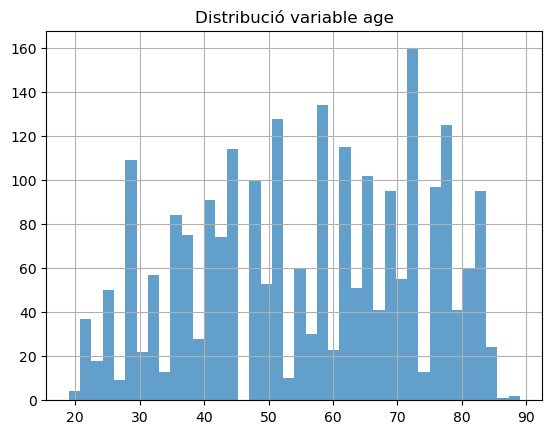

In [11]:
train['age'].hist(bins=40, alpha=0.7)
print ( f'Number of unique values in age :{train['age'].nunique()}')
plt.title('Distribució variable age')
plt.show()

Idea: Potser ho podem juntar per grups d'edat ? 

In [12]:
import pandas as pd

X_num = train.select_dtypes(include="number")

Q1 = X_num.quantile(0.10)
Q3 = X_num.quantile(0.90)
IQR = Q3 - Q1

outliers = (
    (X_num < Q1 - 1.5 * IQR) |
    (X_num > Q3 + 1.5 * IQR)
)

print("Nombre d'outliers per variable:")
print(outliers.sum().sort_values(ascending=False))

Nombre d'outliers per variable:
creatinine_mg_dl       34
length_of_stay_days    12
sodium_mmol_l          10
glucose_mg_dl           6
age                     0
bmi                     0
systolic_bp             0
diastolic_bp            0
spo2                    0
temperature_c           0
respiratory_rate        0
heart_rate              0
hemoglobin_g_dl         0
num_medications         0
prior_visits_12m        0
total_nuls              0
dtype: int64


In [13]:
def remove_outliers(df, column):   
    Q1 = df[column].quantile(0.05)
    Q3 = df[column].quantile(0.95)
    IQR = Q3 - Q1   
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR    
    df_out = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df_out

train = remove_outliers(train, 'creatinine_mg_dl')
train = remove_outliers(train, 'length_of_stay_days')
train = remove_outliers(train, 'sodium_mmol_l')
train = remove_outliers(train, 'glucose_mg_dl')
train.reset_index(drop=True, inplace=True)

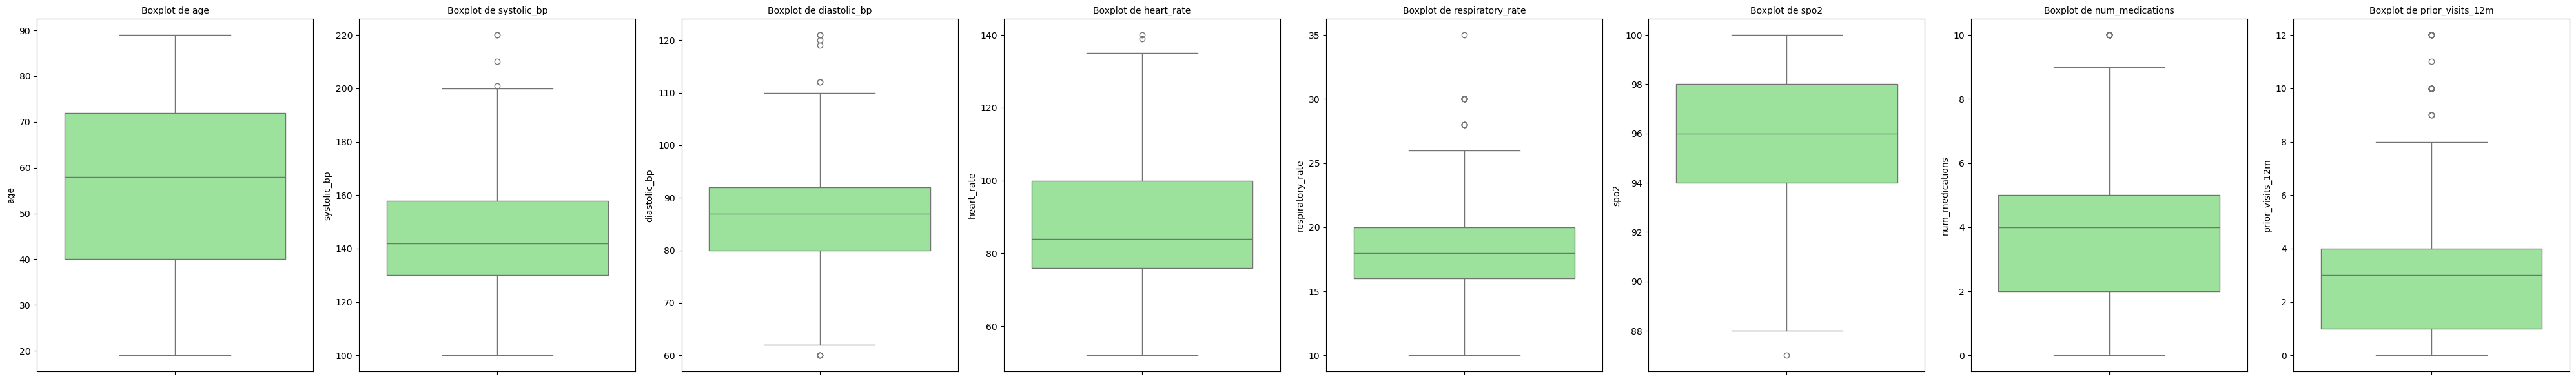

In [14]:
# Crear figura amb dimensions adequades
plt.figure(figsize=(40, 6))  # Amplada major per col·locar múltiples gràfics en fila

# Generar boxplots
for i, col in enumerate(discrete_features):
    plt.subplot(1, len(discrete_features), i + 1)  # 1 fila, tantes columnes com variables
    sns.boxplot(y=train[col], color="lightgreen")  # Orientació vertical
    plt.title(f'Boxplot de {col}', fontsize=10)

# Mostrar gràfics
plt.tight_layout()
plt.show()

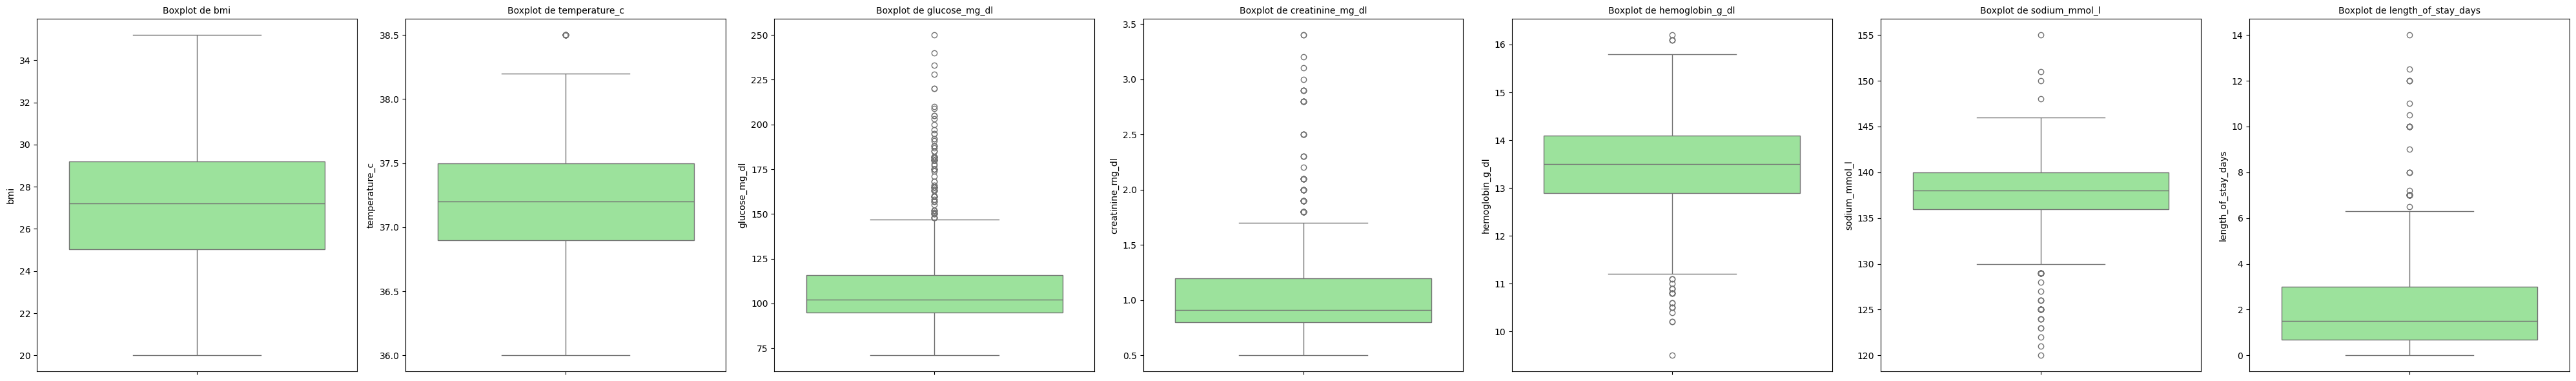

In [15]:
# Crear figura amb dimensions adequades
plt.figure(figsize=(40, 6))  # Amplada major per col·locar múltiples gràfics en fila

# Generar boxplots
for i, col in enumerate(continuous_features):
    plt.subplot(1, len(continuous_features), i + 1)  # 1 fila, tantes columnes com variables
    sns.boxplot(y=train[col], color="lightgreen")  # Orientació vertical
    plt.title(f'Boxplot de {col}', fontsize=10)

# Mostrar gràfics
plt.tight_layout()
plt.show()

( dura molt el codi de dalt, no us espanteu )
Veiem que hi han variables numeriques amb prous outliers :/ ->  hem de pensar q fem

In [16]:
train_bp = train.copy()

train_bp["mean_arterial_pressure"] = (
    train_bp["systolic_bp"] + 2 * train_bp["diastolic_bp"]
) / 3

train_bp.drop(
    columns=["systolic_bp", "diastolic_bp"],
    inplace=True
)

num_features = [
     'age', 'bmi', 'heart_rate', 
    'respiratory_rate', 'temperature_c', 'glucose_mg_dl', 'spo2',
    'creatinine_mg_dl', 'hemoglobin_g_dl', 'sodium_mmol_l',
    'num_medications', 'prior_visits_12m', 'length_of_stay_days', 
     'mean_arterial_pressure'
]

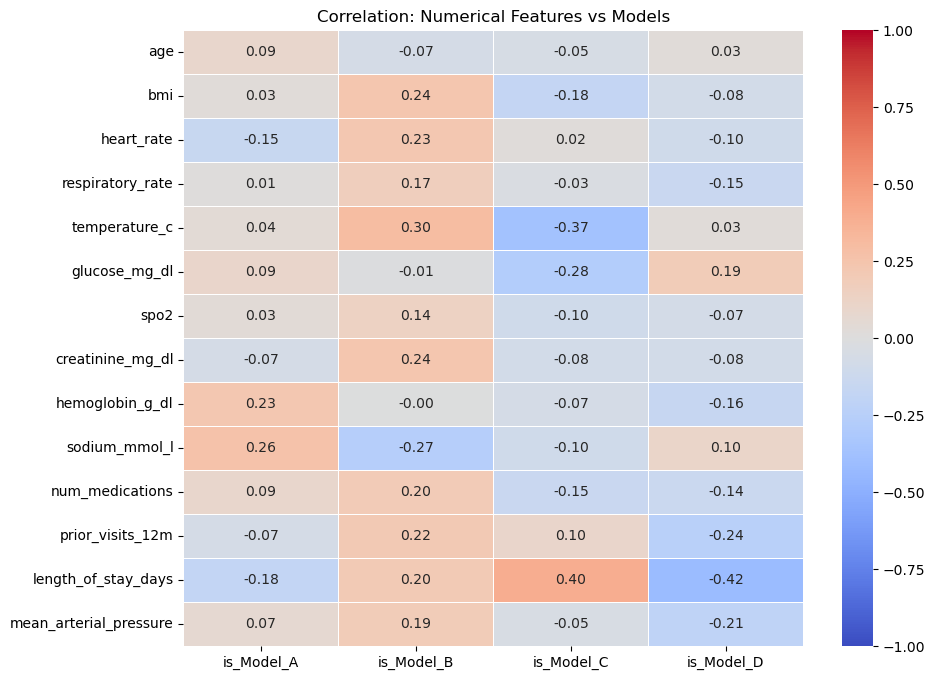

In [17]:
y_encoded = pd.get_dummies(train["label"], prefix="is")

correlation_matrix = pd.concat(
    [train_bp[num_features], y_encoded],
    axis=1
).corr()

# Mostrar solo correlaciones entre features numéricas y output
correlation_matrix = correlation_matrix.loc[
    num_features, y_encoded.columns
]

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    linewidths=0.4,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation: Numerical Features vs Models")
plt.show()


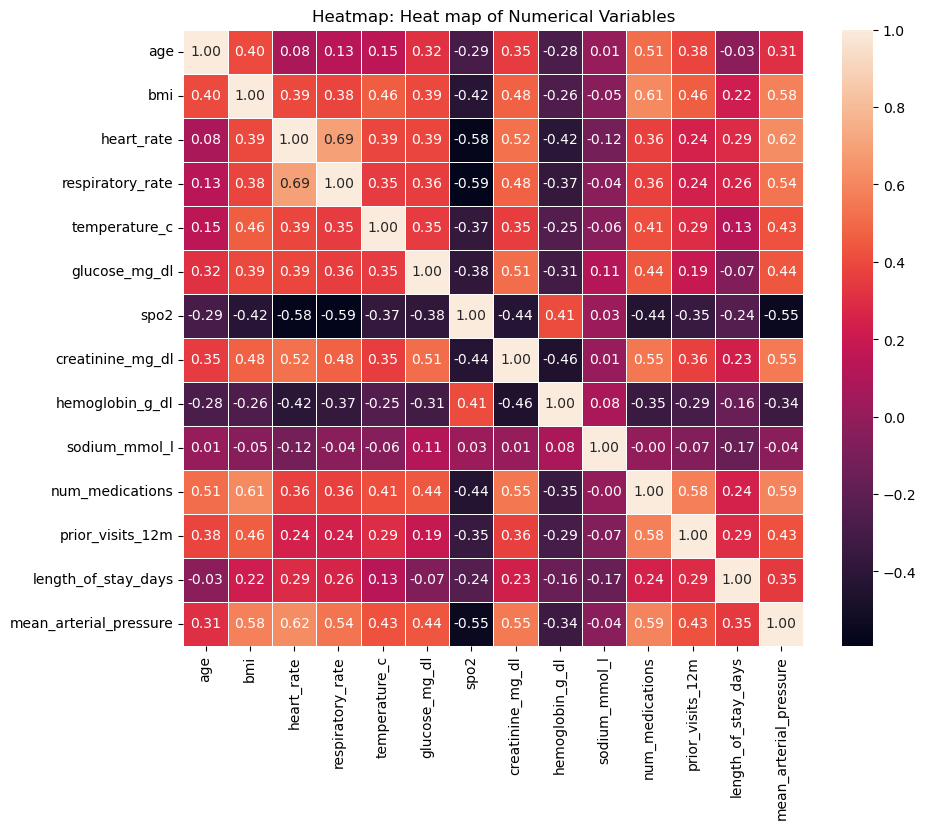

In [18]:

plt.figure(figsize=(10, 8))
correlation_matrix = train_bp[num_features].corr()
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    #cmap="Greens", 
    fmt=".2f", 
    linewidths=0.4
)
plt.title("Heatmap: Heat map of Numerical Variables")
plt.show()

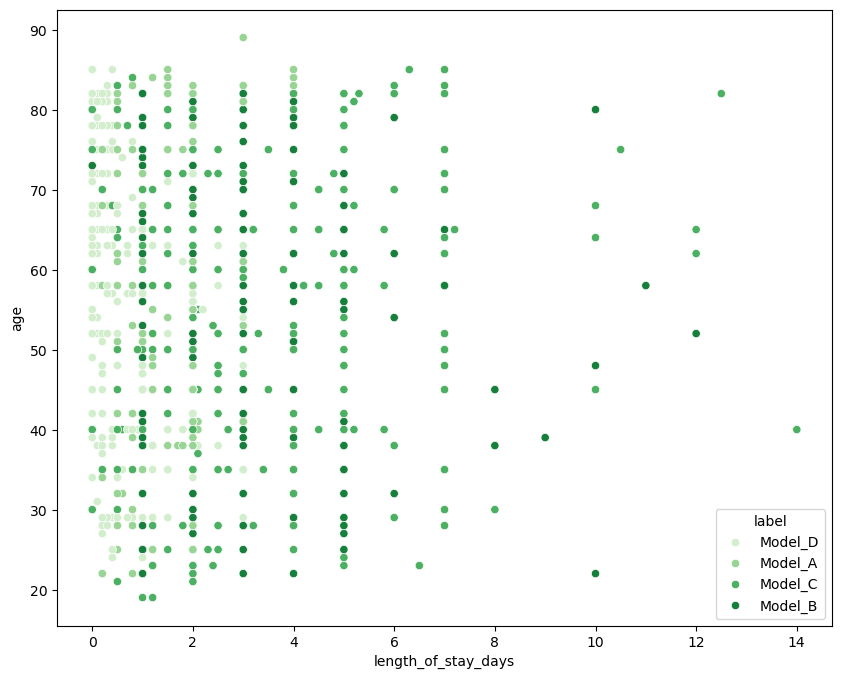

In [19]:
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=train, 
    x="length_of_stay_days", 
    y="age",
    hue = "label",
    palette="Greens"
    #color="lightgreen",
    )

plt.xlabel("length_of_stay_days")
plt.ylabel("age")

plt.show()

## EVALUACIÓ AMB LOGICAL REGRESSOR

De momento solo provamos con train.csv asi el "test" que nos salga sera como "evaluation"

In [65]:
#cargar data
train = pd.read_csv('./train.csv')

In [66]:
print(f"Files originals: {len(train)}")

# Directament amb dropna indicant el mínim de valors no nuls que necessites per fila (per exemple, si tens 26 columnes en total, exigir un mínim de 22 columnes amb dades)
train = train.dropna(thresh=22).copy()


print(f"Files després de netejar: {len(train)}")

Files originals: 2400
Files després de netejar: 2392


remove outliers:

In [67]:
def remove_outliers(df, column):   
    Q1 = df[column].quantile(0.05)
    Q3 = df[column].quantile(0.95)
    IQR = Q3 - Q1   
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR    
    df_out = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    return df_out

# train = remove_outliers(train, 'creatinine_mg_dl')
# train = remove_outliers(train, 'length_of_stay_days')
# train = remove_outliers(train, 'sodium_mmol_l')
# train = remove_outliers(train, 'glucose_mg_dl')
# train.reset_index(drop=True, inplace=True)

In [68]:
X = train.drop(columns=["id","label"])
y = train["label"]

feature engineering:

In [69]:
X["mean_arterial_pressure"] = (
    X["systolic_bp"] + 2 * X["diastolic_bp"]
) / 3

X.drop(
    columns=["systolic_bp", "diastolic_bp"],
    inplace=True
)

X["bmi_age_interaction"] = (
        X["bmi"] * X["age"]
    )

X.drop(
    columns=["age"],
    inplace=True
)


separete train / test : (fent cross-validation no cal)

In [70]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

divide the different variables:

In [71]:
# Variables numéricas discretas
discrete_features = [
    #"age",
    #"systolic_bp",
    #"diastolic_bp",
    "heart_rate",
    "respiratory_rate",
    "spo2",
    "num_medications",
    "prior_visits_12m",
    "mean_arterial_pressure",
]

# Variables numéricas continuas
continuous_features = [
    "bmi",
    "temperature_c",
    "glucose_mg_dl",
    "creatinine_mg_dl",
    "hemoglobin_g_dl",
    "sodium_mmol_l",
    "length_of_stay_days",
    "bmi_age_interaction",
]

# Variables categóricas
cat_features = [
    "sex",
    "smoking_status",
    "encounter_type",
    "diabetes",
    "hypertension",
    "chronic_kidney_disease",
    "primary_diagnosis",
    "discharge_destination",
    "readmitted_30d",
]

In [72]:
# Pipeline para discretas
discrete_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

# Pipeline para continuas
continuous_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler()),
])

# Pipeline para categóricas
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

In [73]:
# Keep length_of_stay_days out of the regular continuous pipeline
other_continuous_features = [
    col for col in continuous_features
    if col != "length_of_stay_days"
]


length_of_stay_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("spline", SplineTransformer(
        n_knots=4,
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
])

spline_preprocessor = ColumnTransformer([
    ("discrete", discrete_pipeline, discrete_features),
    ("continuous", continuous_pipeline, other_continuous_features),
    ("length_of_stay_spline", length_of_stay_pipeline,
     ["length_of_stay_days"]),
    ("categorical", cat_pipeline, cat_features),
])

model_spline = Pipeline([
    ("preprocessor", spline_preprocessor),
    ("classifier", LogisticRegression(
        penalty=None,
        max_iter=5000,
        random_state=42
    )),
])

In [74]:
preprocessor = ColumnTransformer([
    ("discrete", discrete_pipeline, discrete_features),
    ("continuous", continuous_pipeline, continuous_features),
    ("categorical", cat_pipeline, cat_features),
])

el modelo:

In [75]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,
        penalty=None,
        random_state=42
    ))
])

In [76]:
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Train accuracy:", accuracy_score(y_train, model.predict(X_train)))
print("Validation accuracy:", accuracy_score(y_test, y_pred))


Train accuracy: 0.807109252483011
Validation accuracy: 0.8121085594989561


using cross-validation with k-fold for a better accuracy score:

In [77]:
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)
scores = cross_val_score(
    model_spline,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

print("Accuracy for each fold:", scores.round(4))
print("Mean validation accuracy:", round(scores.mean(), 4))
print("Variation between folds:", round(scores.std(), 4))

Accuracy for each fold: [0.8205 0.7975 0.7406 0.8013 0.818  0.7933 0.7683 0.7552 0.8305 0.7824
 0.7787 0.7912 0.7762 0.8033 0.7887 0.7766 0.7745 0.795  0.7824 0.795
 0.7975 0.8267 0.7866 0.7699 0.7845]
Mean validation accuracy: 0.7894
Variation between folds: 0.0206


(
without vars 0.7781 -> kaggle: 0.71

with vars and no og: 0.7753 -> kaggle: 0.7225

with vars and og: 0.7775

without mean arterial: 0.777

with vars and no bps but yes age: 0.7749

without bmi age with mean arterial and ogs: 0.7783

without bmi age with mean arterial but no bps: 0.7761
)

ens quedem amb les 2 features noves pq ha fet millor al kaggle tot i que no hem provat amb les noves i les antigues juntes

spline length of days: 0.7825 

amb outliers i indicator: 0.7837

amb outliers, indicator i spline: 0.7881 -> kaggle: 0.73

si fem remove outliers elimina també les files amb missing values, llavors baixa de tenir 2400 files a tenir-ne 1189. llavors encara que la accuracy sigui millor al final és menys generalitzable perquè entrena i comprova amb molta menys informació. 

model 1 unica nova feature:
- train-> 0.8338
- eval -> 0.8025

model 2 noves features:
- train-> 0.8317
- eval -> 0.8067

model bàsic:
- train-> 0.8166
- eval -> 0.7583
- test -> 0.71750

sense 'sodium_mmol_l':  -> no millora, no provem per entregar
- train-> 0.8078125
- eval -> 0.7416

sense 'spo2':
- train -> 0.788
- eval -> 0.731

sense 'age':        -> podem provar de modificar la variable age per grups d'edat ja que veiem que actualment no ajuda res al model
- train-> 0.8197
- eval -> 0.7604

afegint 'age_group' i deixant 'age':
- train-> 0.8197
- eval -> 0.7562

afegint 'age_group' i eliminant 'age':
- train ->0.8208
- eval -> 0.7562

SEPARANT NUMERIQUES:
- train ->0.8156
- eval -> 0.7604
- test -> 0.71750

Treient 0.9 i 0.1 dels quartils de outliers:
- train ->0.8279
- eval -> 0.7725

Treient 0.85 i 0.15 dels quartils de outliers:
- train ->0.83687
- eval -> 0.7723

Treient 0.95 i 0.05 dels quartils de outliers:
- train ->0.8233
- eval -> 0.7941

adding to our highest validation accuracy

signed log transform on all continuous features:
- train -> 0.8286
- eval -> 0.8193
(al kaggle baixa)




model 1 unica nova feature:
- train-> 0.8338
- eval -> 0.8025

model 2 noves features:
- train-> 0.8317
- eval -> 0.8067

model bàsic:
- train-> 0.8166
- eval -> 0.7583
- test -> 0.71750

sense 'sodium_mmol_l':  -> no millora, no provem per entregar
- train-> 0.8078125
- eval -> 0.7416

sense 'spo2':
- train -> 0.788
- eval -> 0.731

sense 'age':        -> podem provar de modificar la variable age per grups d'edat ja que veiem que actualment no ajuda res al model
- train-> 0.8197
- eval -> 0.7604

afegint 'age_group' i deixant 'age':
- train-> 0.8197
- eval -> 0.7562

afegint 'age_group' i eliminant 'age':
- train ->0.8208
- eval -> 0.7562

SEPARANT NUMERIQUES:
- train ->0.8156
- eval -> 0.7604
- test -> 0.71750

Treient 0.9 i 0.1 dels quartils de outliers:
- train ->0.8279
- eval -> 0.7725

Treient 0.85 i 0.15 dels quartils de outliers:
- train ->0.83687
- eval -> 0.7723

Treient 0.95 i 0.05 dels quartils de outliers:
- train ->0.8233
- eval -> 0.7941

adding to our highest validation accuracy

signed log transform on all continuous features:
- train -> 0.8286
- eval -> 0.8193
(al kaggle baixa)




In [78]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nMatriu de confusió:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8121085594989561

Matriu de confusió:
[[ 83  10   9  18]
 [ 13  95   8   3]
 [  4   7 106   3]
 [  9   4   2 105]]

Classification report:
              precision    recall  f1-score   support

     Model_A       0.76      0.69      0.72       120
     Model_B       0.82      0.80      0.81       119
     Model_C       0.85      0.88      0.87       120
     Model_D       0.81      0.88      0.84       120

    accuracy                           0.81       479
   macro avg       0.81      0.81      0.81       479
weighted avg       0.81      0.81      0.81       479



# TO SUMBIT

Aqui si que utilitzarem el test.csv. (Millor basar-nos només en el de dalt)

In [88]:
train = pd.read_csv('./train.csv')
test = pd.read_csv('./test.csv')

remove outliers:

In [89]:
train = train.dropna(thresh=22).copy()

In [90]:
# train = remove_outliers(train, 'creatinine_mg_dl')
# train = remove_outliers(train, 'length_of_stay_days')
# train = remove_outliers(train, 'sodium_mmol_l')
# train = remove_outliers(train, 'glucose_mg_dl')
# train.reset_index(drop=True, inplace=True)

feature engineering:

In [91]:
train["mean_arterial_pressure"] = (
    train["systolic_bp"] + 2 * train["diastolic_bp"]
) / 3

train.drop(
    columns=["systolic_bp", "diastolic_bp"],
    inplace=True
)

train["bmi_age_interaction"] = (
        train["bmi"] * train["age"]
    )

train.drop(
    columns=["age"],
    inplace=True
)

test["mean_arterial_pressure"] = (
    test["systolic_bp"] + 2 * test["diastolic_bp"]
) / 3

test.drop(
    columns=["systolic_bp", "diastolic_bp"],
    inplace=True
)

test["bmi_age_interaction"] = (
        test["bmi"] * test["age"]
    )

test.drop(
    columns=["age"],
    inplace=True
)

Defining X and y:

In [92]:

X_train = train.drop(columns=["label","id"])
y_train = train["label"]

test_ids = test["id"]
X_test = test.drop(columns=["id"])

In [93]:
# Pipeline para discretas
discrete_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

# Pipeline para continuas
continuous_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", RobustScaler()),
])

# Pipeline para categóricas
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

In [94]:
#intentant spline per length_of_stay_days

# Keep length_of_stay_days out of the regular continuous pipeline
other_continuous_features = [
    col for col in continuous_features
    if col != "length_of_stay_days"
]


length_of_stay_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("spline", SplineTransformer(
        n_knots=4,
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
])

spline_preprocessor = ColumnTransformer([
    ("discrete", discrete_pipeline, discrete_features),
    ("continuous", continuous_pipeline, other_continuous_features),
    ("length_of_stay_spline", length_of_stay_pipeline,
     ["length_of_stay_days"]),
    ("categorical", cat_pipeline, cat_features),
])

model_spline = Pipeline([
    ("preprocessor", spline_preprocessor),
    ("classifier", LogisticRegression(
        penalty=None,
        max_iter=5000,
        random_state=42
    )),
])

In [95]:
preprocessor = ColumnTransformer([
    ("discrete", discrete_pipeline, discrete_features),
    ("continuous", continuous_pipeline, continuous_features),
    ("categorical", cat_pipeline, cat_features),
])

In [96]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=4000,
        penalty=None,
        random_state=42
    ))
])

In [97]:
#Ja tenim totes les configuracions d'abans aixi que nomes ens cal tornar a evaluar el model trobat

model_spline.fit(X_train, y_train)

predictions = model_spline.predict(X_test)

# Create the submission DataFrame
submission = pd.DataFrame({
    "id": test_ids,
    "label": predictions
})

# Save to CSV
submission.to_csv("submission_2.csv", index=False)

print("Train accuracy:", accuracy_score(y_train, model_spline.predict(X_train)))
print(submission.head())
print("Submission shape:", submission.shape)

Train accuracy: 0.8164715719063546
                                 id    label
0  0102f98c5fd7ed84754c58fe0d7f013f  Model_D
1  e2fa3e497f5bdb8c79748c7c0611fad0  Model_B
2  818a6ec782d097abc1ce67c42299d06a  Model_A
3  54e46a096cb47b5499a986477be83061  Model_B
4  5da9e7a746719fc3950c6e579c82bfa1  Model_A
Submission shape: (1600, 2)
